In [32]:
from ultralytics import YOLO
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

print("Current directory:", Path.cwd())
print("Files:", list(Path.cwd().iterdir()))

Current directory: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks
Files: [PosixPath('/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/.ipynb_checkpoints'), PosixPath('/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/01_dataset_exploration.ipynb'), PosixPath('/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/train.ipynb'), PosixPath('/home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/notebooks/dataset_augmentation.ipynb')]


In [33]:

# Find the project root automatically
DATA_FOLDER = Path("data") / "Single Object trajectory"

PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / DATA_FOLDER).is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project data folder. "
        "Check your folder structure."
    )

DATA_ROOT = PROJECT_ROOT / DATA_FOLDER

print("Project root:", PROJECT_ROOT)
print("Data root:", DATA_ROOT)

Project root: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project
Data root: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/data/Single Object trajectory


In [34]:
def find_video_dirs(split):
    split_dir = DATA_ROOT / split

    if not split_dir.is_dir():
        raise FileNotFoundError(split_dir)

    return {
        p.name: p
        for p in sorted(split_dir.iterdir())
        if p.is_dir() and (p / "input").is_dir()
    }


train_dirs = find_video_dirs("train")
val_dirs = find_video_dirs("val")
test_dirs = find_video_dirs("test")

print("Training videos:", list(train_dirs))
print("Validation videos:", list(val_dirs))
print("Test videos:", list(test_dirs))

Training videos: ['Person1', 'Person3', 'Person4', 'sofaMan1', 'sofaMan2', 'sofaMan4']
Validation videos: ['Person2', 'sofaMan3']
Test videos: ['Boat1', 'Boat2']


In [35]:
def generate_angles(
    num_frames,
    max_angle=50,
    max_step=10,
    seed=None
):
    rng = np.random.default_rng(seed)

    angles = np.zeros(num_frames, dtype=np.float32)

    velocity = 0.0

    for t in range(1, num_frames):

        velocity = np.clip(
            0.85 * velocity + rng.normal(0, 0.4 * max_step),
            -max_step,
            max_step
        )

        angles[t] = np.clip(
            angles[t-1] + velocity,
            -max_angle,
            max_angle
        )

    return angles


In [36]:
import cv2
import numpy as np


def calculate_zoom(w, h, max_angle=15):
    """
    Calculate a constant zoom factor that prevents
    empty borders for rotations within ±max_angle degrees.
    """

    angles = np.linspace(-max_angle, max_angle, 181)

    zoom_factors = []

    for angle in angles:

        theta = np.deg2rad(angle)

        c = abs(np.cos(theta))
        s = abs(np.sin(theta))

        zoom_x = c + (h / w) * s
        zoom_y = c + (w / h) * s

        zoom_factors.append(max(zoom_x, zoom_y))

    # Small safety margin
    return max(zoom_factors) * 1.005


def rotate_images(frames, angles, max_angle=15):

    rotated_frames = []
    matrices = []

    assert len(frames) == len(angles)
    assert np.max(np.abs(angles)) <= max_angle + 1e-5

    h, w = frames[0].shape[:2]

    # One constant zoom for the entire sequence
    zoom = calculate_zoom(w, h, max_angle)

    for frame, angle in zip(frames, angles):

        M = cv2.getRotationMatrix2D(
            (w / 2, h / 2),
            float(angle),
            zoom
        )

        rotated = cv2.warpAffine(
            frame,
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=(0, 0, 0)
        )

        rotated_frames.append(rotated)
        matrices.append(M)

    return (
        np.stack(rotated_frames),
        np.stack(matrices)
    )

In [37]:
from pathlib import Path
import csv
import hashlib
import re
import numpy as np
import cv2

from torch.utils.data import Dataset


class RotatedCDnetDataset(Dataset):

    def __init__(
        self,
        dataset_id,
        video_dir,
        mode="train",
        seed=42,
        max_angle=360,
        max_step=50,
        log_root="Logs",
    ):

        # Dataset identification
        self.dataset_id = str(dataset_id)

        if not re.fullmatch(
            r"[A-Za-z0-9][A-Za-z0-9_.-]*",
            self.dataset_id
        ):
            raise ValueError("Invalid dataset ID")

        # Configuration
        self.video_dir = Path(video_dir).expanduser().resolve()
        self.mode = mode
        self.seed = int(seed)
        self.max_angle = float(max_angle)
        self.max_step = float(max_step)
        self.epoch = 0

        if self.mode not in ("train", "fixed"):
            raise ValueError("mode must be 'train' or 'fixed'")

        if self.max_angle < 0 or self.max_step < 0:
            raise ValueError("Rotation limits must be nonnegative")

        # Load paths to ALL frames in the video
        input_dir = self.video_dir / "input"

        if not input_dir.is_dir():
            raise FileNotFoundError(input_dir)

        self.frame_paths = sorted(
            p for p in input_dir.iterdir()
            if p.is_file()
            and p.name.startswith("in")
            and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )

        if not self.frame_paths:
            raise ValueError(f"No frames found in {input_dir}")

        self.num_frames = len(self.frame_paths)

        # Portable video identifier
        self.source_video = (
            f"{self.video_dir.parent.name}/{self.video_dir.name}"
        )

        # Logging directory
        self.log_dir = Path(log_root) / self.dataset_id
        self.log_dir.mkdir(parents=True, exist_ok=True)

        # Dataset information
        self.info = {
            "dataset_id": self.dataset_id,
            "source_video": self.source_video,
            "mode": self.mode,
            "seed": self.seed,
            "num_frames": self.num_frames,
            "max_angle": self.max_angle,
            "max_step": self.max_step,
            "rotation_version": "whole_video_v1",
        }

        # Save dataset configuration
        info_path = self.log_dir / "dataset_info.csv"

        if info_path.exists():

            with info_path.open(newline="") as f:
                previous = next(csv.DictReader(f), None)

            if previous is None or any(
                str(value) != previous.get(key)
                for key, value in self.info.items()
            ):
                raise ValueError(
                    f"Dataset ID already exists with "
                    f"different settings: {self.dataset_id}"
                )

        else:

            with info_path.open("w", newline="") as f:

                writer = csv.DictWriter(
                    f,
                    fieldnames=list(self.info)
                )

                writer.writeheader()
                writer.writerow(self.info)

        # Generate rotation labels and CSV
        self.export_angles()

    def __len__(self):

        # ONE dataset sample = ONE complete video
        return 1

    def _sample_seed(self, epoch):

        key = (
            f"{self.seed}:"
            f"{self.source_video}:"
            f"{epoch}"
        )

        digest = hashlib.sha256(
            key.encode()
        ).digest()

        return int.from_bytes(
            digest[:8],
            "little"
        )

    def _angles(self, epoch):

        return generate_angles(
            num_frames=self.num_frames,
            max_angle=self.max_angle,
            max_step=self.max_step,
            seed=self._sample_seed(epoch),
        )

    def export_angles(self):

        epoch = (
            self.epoch
            if self.mode == "train"
            else 0
        )

        path = (
            self.log_dir
            / f"angles_epoch_{epoch:03d}.csv"
        )

        if path.exists():
            return path

        # Generate ONE continuous trajectory
        angles = self._angles(epoch)

        deltas = np.diff(
            angles,
            prepend=angles[0]
        )

        with path.open("w", newline="") as f:

            writer = csv.writer(f)

            writer.writerow([
                "dataset_id",
                "epoch",
                "frame_idx",
                "original_frame",
                "angle_deg",
                "delta_deg"
            ])

            for i, (frame, angle, delta) in enumerate(
                zip(self.frame_paths, angles, deltas)
            ):

                writer.writerow([
                    self.dataset_id,
                    epoch,
                    i,
                    frame.name,
                    float(angle),
                    float(delta)
                ])

        return path

    def set_epoch(self, epoch):

        self.epoch = int(epoch)

        return self.export_angles()

    def __getitem__(self, idx):

        if idx != 0:
            raise IndexError(
                "This dataset contains one complete video"
            )

        # Load ALL original frames
        frames = []

        for path in self.frame_paths:

            img = cv2.imread(str(path))

            if img is None:
                raise ValueError(
                    f"Cannot read image: {path}"
                )

            frames.append(img)

        frames = np.stack(frames)

        # Determine current epoch
        epoch = (
            self.epoch
            if self.mode == "train"
            else 0
        )

        # ONE rotation trajectory for entire video
        angles = self._angles(epoch)

        # Rotate all frames
        rotated, matrices = rotate_images(
            frames,
            angles,
            max_angle=self.max_angle
        )

        return {
            "original_frames": frames,
            "rotated_frames": rotated,
            "angles_deg": angles,
            "matrices": matrices,
            "dataset_id": self.dataset_id,
        }

In [47]:
# One dataset = one source video, with a unique experiment ID.
# Re-running the same ID and settings is safe; changed settings require a new ID.
video = "Person1"
train_dataset = RotatedCDnetDataset(
    dataset_id="90",
    video_dir=train_dirs[video],
    mode="train",
    seed=7,
    max_angle=90,
    max_step=50,
    log_root=PROJECT_ROOT / "Logs",
)

video = "sofaMan3"
val_dataset = RotatedCDnetDataset(
    dataset_id="sofaMan3_val_angle90_step50_seed42_v1",
    video_dir=val_dirs[video],
    mode="fixed",
    seed=42,
    max_angle=90,
    max_step=50,
    log_root=PROJECT_ROOT / "Logs",
)
print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))


Training windows: 1
Validation windows: 1


In [48]:
# The CSV files already exist after creating the dataset.
import pandas as pd
print("Dataset ID:", train_dataset.dataset_id)
print("Number of windows:", len(train_dataset))
print("Log directory:", train_dataset.log_dir)
display(pd.read_csv(train_dataset.log_dir / "dataset_info.csv"))
display(pd.read_csv(train_dataset.log_dir / "angles_epoch_000.csv").head())

# Example: generate a new trajectory for training epoch 1 and save its labels.
# train_dataset.set_epoch(1)


Dataset ID: 90
Number of windows: 1
Log directory: /home/hannes-karlsson/Chalmers/courses/DeepMachineLearning/Project/Logs/90


,dataset_id,source_video,mode,seed,num_frames,max_angle,max_step,rotation_version
0,90,train/Person1,train,7,103,90.0,50.0,whole_video_v1


,dataset_id,epoch,frame_idx,original_frame,angle_deg,delta_deg
0,90,0,0,in000300.jpg,0.000000,0.000000
1,90,0,1,in000301.jpg,-18.832195,-18.832195
2,90,0,2,in000302.jpg,-68.832199,-50.000004
3,90,0,3,in000303.jpg,-90.000000,-21.167801
4,90,0,4,in000304.jpg,-90.000000,0.000000


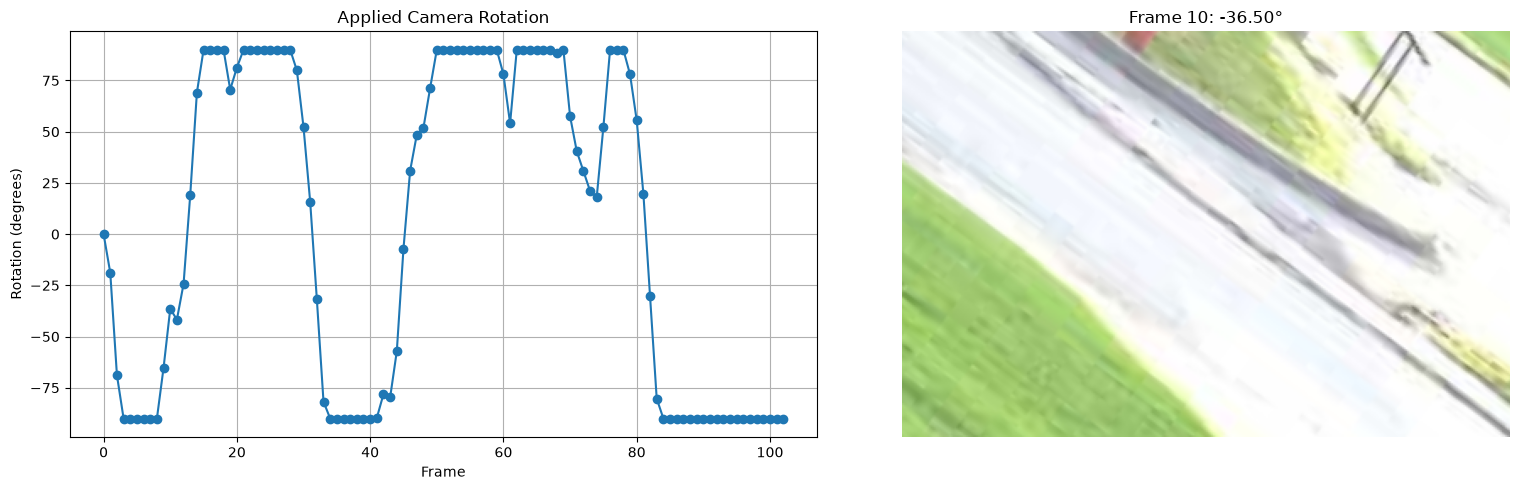

In [49]:
# Get one sample from the dataset
train_dataset.set_epoch(0)
sample = train_dataset[0]

frames = sample["rotated_frames"]
angles = sample["angles_deg"]

# Plot the rotation trajectory
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# LEFT: Rotation trajectory
axes[0].plot(
    np.arange(len(angles)),
    angles,
    marker="o"
)

axes[0].set_xlabel("Frame")
axes[0].set_ylabel("Rotation (degrees)")
axes[0].set_title("Applied Camera Rotation")
axes[0].grid(True)

# RIGHT: Example rotated frame
frame_idx = 10

axes[1].imshow(
    cv2.cvtColor(
        frames[frame_idx],
        cv2.COLOR_BGR2RGB
    )
)

axes[1].set_title(
    f"Frame {frame_idx}: {angles[frame_idx]:.2f}°"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

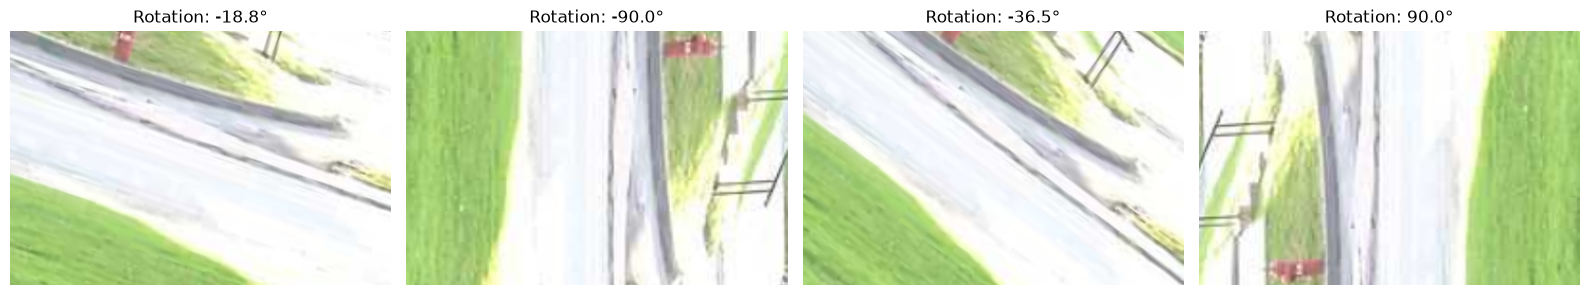

In [50]:
sample = train_dataset[0]

frames = sample["rotated_frames"]
angles = sample["angles_deg"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

indices = [1, 5, 10, 15]

for ax, i in zip(axes, indices):

    ax.imshow(
        cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB)
    )

    ax.set_title(f"Rotation: {angles[i]:.1f}°")
    ax.axis("off")

plt.tight_layout()
plt.show()